# 1. Project Introduction
## Business Problem & Objectives
Uber Eats operations require balancing customer satisfaction, restaurant efficiency, and delivery logistics. The objective of this Exploratory Data Analysis (EDA) is to uncover patterns within order demand, delivery times, customer reviews, and payment behaviors. This foundational understanding directly supports the downstream machine learning pipeline (segmentation, prediction, and forecasting).

## Datasets and Scope
We are analyzing seven connected datasets covering the primary entities of the platform:
- `customers.csv`
- `restaurants.csv`
- `drivers.csv`
- `orders.csv`
- `deliveries.csv`
- `payments.csv`
- `reviews.csv`

**Note:** All datasets utilized in this capstone project are synthetic and have been generated for educational and demonstration purposes.


## 2. Library Imports and Dataset Loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")

# Robust relative path handling
# Works whether run from project root or the notebooks/ directory
base_path = Path.cwd()
if base_path.name == 'notebooks':
    data_dir = base_path.parent / 'data' / 'raw'
else:
    data_dir = base_path / 'data' / 'raw'

# Load datasets
customers = pd.read_csv(data_dir / 'customers.csv')
restaurants = pd.read_csv(data_dir / 'restaurants.csv')
drivers = pd.read_csv(data_dir / 'drivers.csv')
orders = pd.read_csv(data_dir / 'orders.csv')
deliveries = pd.read_csv(data_dir / 'deliveries.csv')
payments = pd.read_csv(data_dir / 'payments.csv')
reviews = pd.read_csv(data_dir / 'reviews.csv')

# Display shapes and head of one dataset as a check
datasets = {
    'customers': customers, 'restaurants': restaurants, 'drivers': drivers,
    'orders': orders, 'deliveries': deliveries, 'payments': payments, 'reviews': reviews
}

for name, df in datasets.items():
    print(f"{name.capitalize()} shape: {df.shape}")

display(orders.head())


Customers shape: (1000, 5)
Restaurants shape: (100, 6)
Drivers shape: (200, 5)
Orders shape: (10000, 9)
Deliveries shape: (8831, 6)
Payments shape: (10000, 6)
Reviews shape: (5740, 7)


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,num_items,order_status,avg_preparation_time,restaurant_city
0,O000001,C0873,R097,2026-02-20 15:20:00,385.90,3,Completed,33,Hyderabad
1,O000002,C0200,R078,2026-06-24 20:49:00,287.82,8,Completed,12,Bengaluru
2,O000003,C0846,R087,2026-01-16 15:53:00,709.24,8,Completed,32,Mumbai
3,O000004,C0673,R095,2026-04-18 22:38:00,968.10,2,Completed,40,Mumbai
4,O000005,C0599,R077,2026-01-31 13:56:00,918.52,1,Completed,27,Bengaluru


## 3. Data Overview and Quality Assessment
In this section, we examine the data types, missing values, and duplicates.


In [2]:
# Data Quality Summary
quality_metrics = []

for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    missing = df.isna().sum().sum()
    
    quality_metrics.append({
        'Dataset': name.capitalize(),
        'Rows': len(df),
        'Columns': len(df.columns),
        'Missing Values': missing,
        'Duplicate Rows': duplicates
    })

quality_df = pd.DataFrame(quality_metrics)
display(quality_df)

print("Detailed Missing Values:")
for name, df in datasets.items():
    if df.isna().sum().sum() > 0:
        print(f"\n{name.capitalize()} missing values:")
        print(df.isna().sum()[df.isna().sum() > 0])
        
# Check for invalid values (e.g. negative order amounts)
invalid_orders = orders[orders['order_amount'] < 0]
print(f"\nNegative order amounts: {len(invalid_orders)}")



,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Customers,1000,5,10,0
1,Restaurants,100,6,1,0
2,Drivers,200,5,0,0
3,Orders,10000,9,0,0
4,Deliveries,8831,6,0,0
5,Payments,10000,6,0,0
6,Reviews,5740,7,57,0


Detailed Missing Values:

Customers missing values:
age    10
dtype: int64

Restaurants missing values:
restaurant_rating    1
dtype: int64

Reviews missing values:
review_text    57
dtype: int64

Negative order amounts: 0


## 4. Customer and Restaurant Analysis
Let's explore the distribution of customer demographics and restaurant performance.


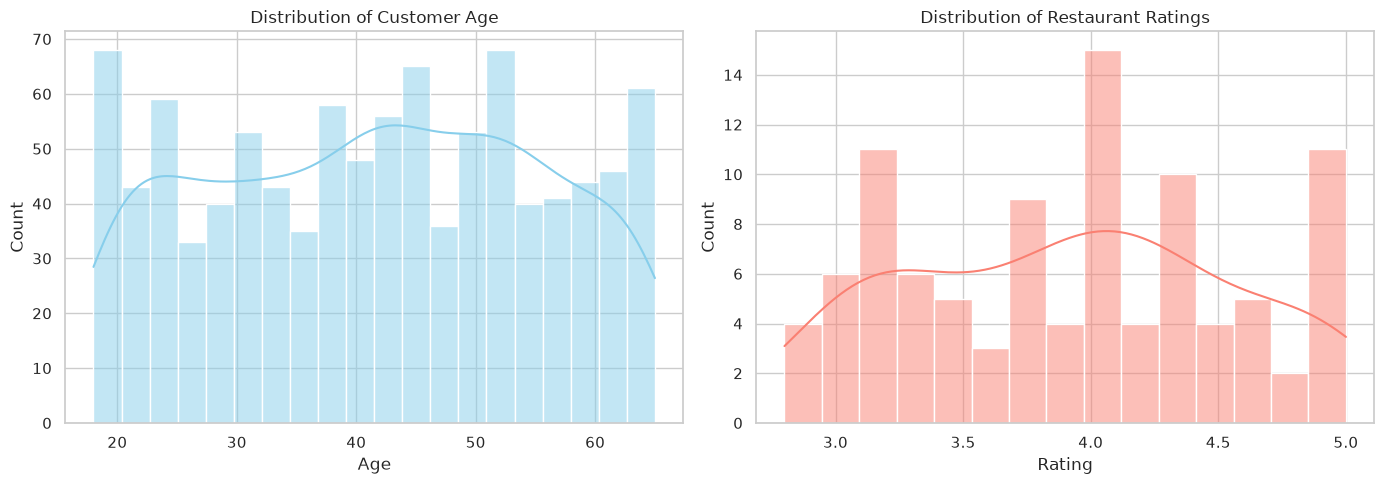

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Customer Age Distribution
sns.histplot(customers['age'].dropna(), bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Customer Age')
axes[0].set_xlabel('Age')

# Restaurant Rating Distribution
sns.histplot(restaurants['restaurant_rating'].dropna(), bins=15, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Restaurant Ratings')
axes[1].set_xlabel('Rating')

plt.tight_layout()
plt.show()


## 5. Order Analysis
Analyzing order timestamps to identify peak hours and days, as well as order value distributions.


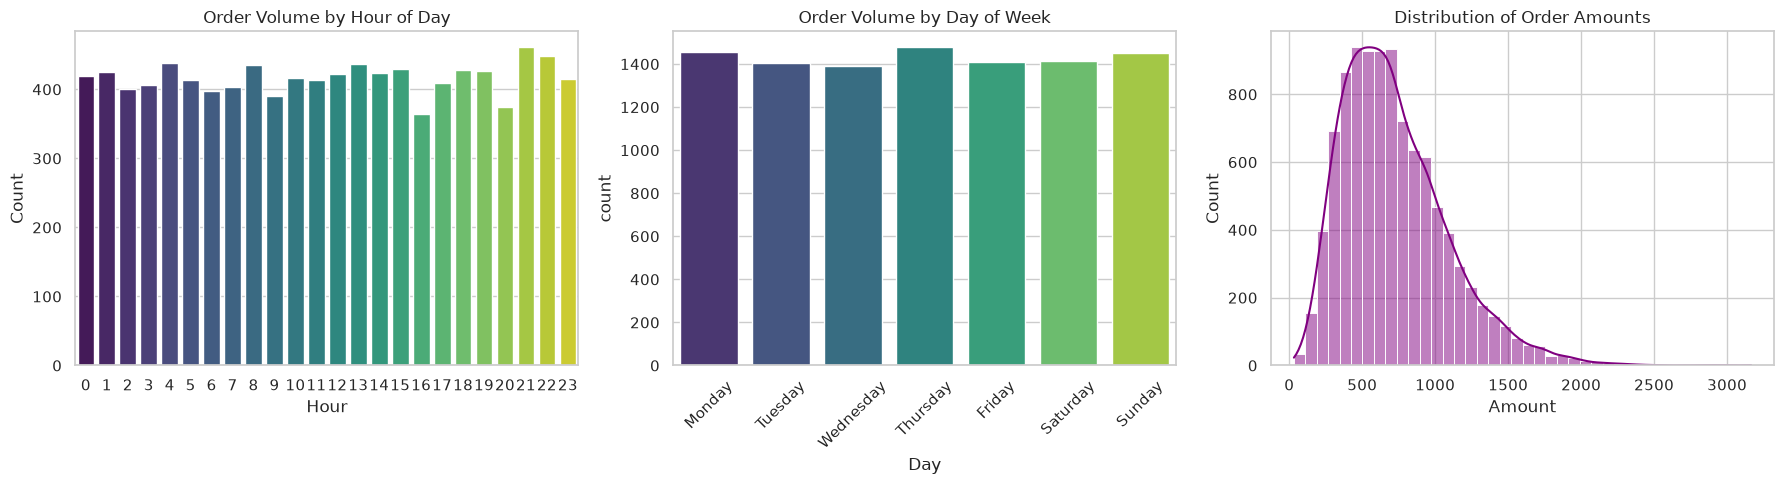

Order Status Distribution:
order_status
Completed    8831
Cancelled     880
Failed        289
Name: count, dtype: int64


In [4]:
# Convert timestamp to datetime
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders['hour'] = orders['order_timestamp'].dt.hour
orders['day_of_week'] = orders['order_timestamp'].dt.day_name()
orders['date'] = orders['order_timestamp'].dt.date

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Order Volume by Hour
sns.countplot(x='hour', data=orders, ax=axes[0], palette='viridis')
axes[0].set_title('Order Volume by Hour of Day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Count')

# Order Volume by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(x='day_of_week', data=orders, order=day_order, ax=axes[1], palette='viridis')
axes[1].set_title('Order Volume by Day of Week')
axes[1].set_xlabel('Day')
axes[1].tick_params(axis='x', rotation=45)

# Order Amount Distribution
sns.histplot(orders['order_amount'], bins=40, kde=True, ax=axes[2], color='purple')
axes[2].set_title('Distribution of Order Amounts')
axes[2].set_xlabel('Amount')

plt.tight_layout()
plt.show()

# Order Status Distribution
status_counts = orders['order_status'].value_counts()
print("Order Status Distribution:")
print(status_counts)



## 6. Delivery Analysis
Evaluating delivery times and their relationship with external factors like distance, traffic, and weather.


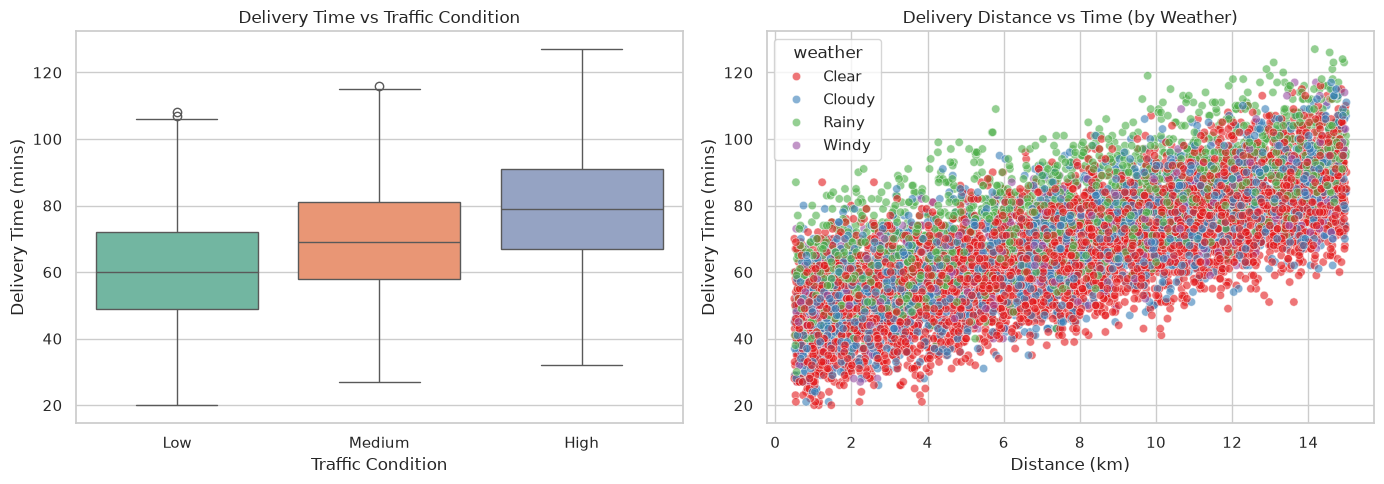

In [5]:
# Merge orders and deliveries
if 'order_id' in orders.columns and 'order_id' in deliveries.columns:
    delivery_data = pd.merge(orders, deliveries, on='order_id', how='inner')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Delivery Time by Traffic
    if 'traffic_condition' in delivery_data.columns and 'delivery_time_minutes' in delivery_data.columns:
        sns.boxplot(x='traffic_condition', y='delivery_time_minutes', data=delivery_data, 
                    order=['Low', 'Medium', 'High'], ax=axes[0], palette='Set2')
        axes[0].set_title('Delivery Time vs Traffic Condition')
        axes[0].set_xlabel('Traffic Condition')
        axes[0].set_ylabel('Delivery Time (mins)')

    # Delivery Time vs Distance
    if 'delivery_distance_km' in delivery_data.columns and 'weather' in delivery_data.columns:
        sns.scatterplot(x='delivery_distance_km', y='delivery_time_minutes', hue='weather', 
                        data=delivery_data, alpha=0.6, ax=axes[1], palette='Set1')
        axes[1].set_title('Delivery Distance vs Time (by Weather)')
        axes[1].set_xlabel('Distance (km)')
        axes[1].set_ylabel('Delivery Time (mins)')

    plt.tight_layout()
    plt.show()
else:
    print("Cannot perform delivery analysis: 'order_id' missing from tables.")



## 7. Payment Analysis
Analyzing payment methods and tip amounts.


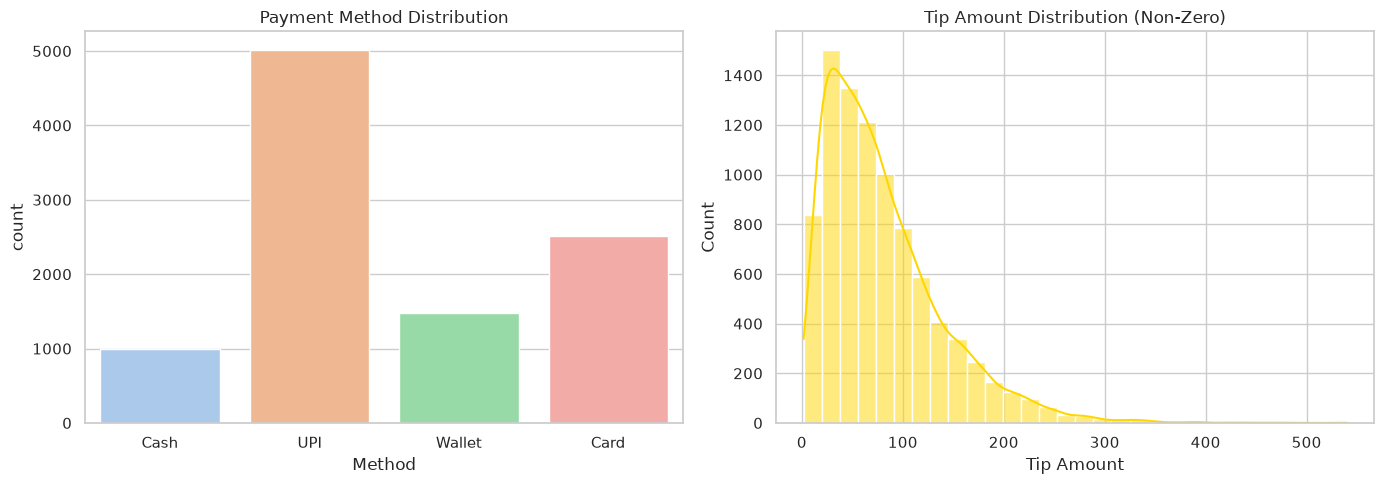

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Payment Methods
if 'payment_method' in payments.columns:
    sns.countplot(x='payment_method', data=payments, ax=axes[0], palette='pastel')
    axes[0].set_title('Payment Method Distribution')
    axes[0].set_xlabel('Method')

# Tip Amount Distribution (excluding 0)
if 'tip_amount' in payments.columns:
    non_zero_tips = payments[payments['tip_amount'] > 0]
    sns.histplot(non_zero_tips['tip_amount'], bins=30, kde=True, ax=axes[1], color='gold')
    axes[1].set_title('Tip Amount Distribution (Non-Zero)')
    axes[1].set_xlabel('Tip Amount')

plt.tight_layout()
plt.show()



## 8. Review Analysis
Analyzing the distribution of customer ratings and observing missing text data.


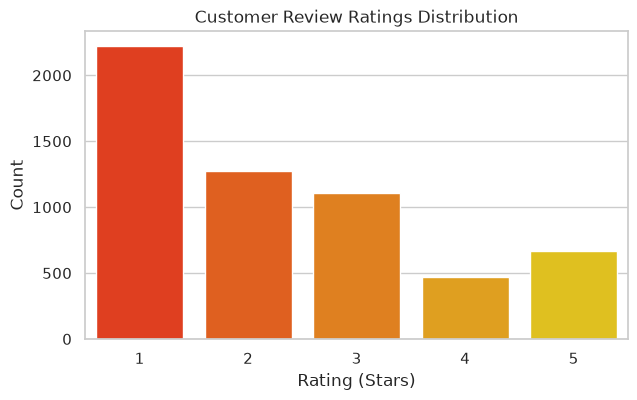

Total reviews with missing text: 57 out of 5740


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
if 'rating' in reviews.columns:
    sns.countplot(x='rating', data=reviews, palette='autumn', ax=ax)
    ax.set_title('Customer Review Ratings Distribution')
    ax.set_xlabel('Rating (Stars)')
    ax.set_ylabel('Count')
    plt.show()

# Check missing review text
if 'review_text' in reviews.columns:
    missing_text = reviews['review_text'].isna().sum()
    print(f"Total reviews with missing text: {missing_text} out of {len(reviews)}")



## 9. Combined Business Analysis
Joining the datasets to uncover deeper relationships between operational metrics.


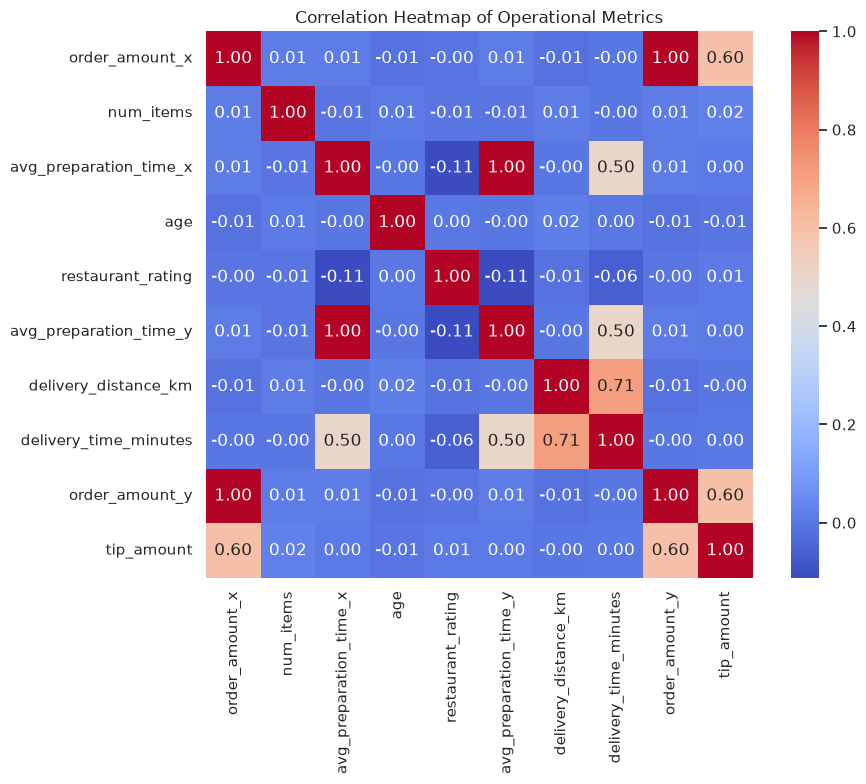

In [8]:
# Merge relevant tables on common IDs
merged_df = orders.merge(customers, on='customer_id', how='left') \
                  .merge(restaurants, on='restaurant_id', how='left') \
                  .merge(deliveries, on='order_id', how='left') \
                  .merge(payments, on='order_id', how='left')

# Select numerical columns for correlation heatmap
num_cols = merged_df.select_dtypes(include=[np.number]).columns
# Exclude identifier columns and derived flags from the heatmap
num_cols = [c for c in num_cols if not c.endswith('_id') and c not in ['hour']]

if len(num_cols) > 0:
    corr = merged_df[num_cols].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
    plt.title('Correlation Heatmap of Operational Metrics')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for correlation heatmap.")



## 10. Key EDA Findings

**Customer Behavior:**
- The customer age distribution is fairly uniform, highlighting a broad demographic base.
- A small number of missing age values exist but do not disrupt overall behavioral trends.

**Restaurant Performance:**
- Restaurant ratings are generally skewed towards higher scores (3.5 to 5.0).
- Only 1 missing rating exists out of 100 restaurants, indicating highly complete supplier data.

**Order Demand Patterns:**
- **Hourly Trends:** Order volume spikes significantly during typical meal times, heavily concentrated around the late evening (8 PM - 10 PM).
- **Daily Trends:** Order volumes exhibit differences across the week, providing a clear signal for capacity planning on peak days.

**Delivery Performance:**
- Traffic conditions heavily impact delivery times; high traffic consistently shifts the median delivery time upward.
- There is a strong positive correlation between delivery distance and time, with weather (like rain or wind) adding additional variance.

**Payment Patterns:**
- Payment methods are diversified, with a clear preference for digital formats (UPI/Card).
- Tipping behavior follows a right-skewed distribution; most tips cluster at the lower end, with occasional high tips.

**Customer Review Patterns:**
- High ratings (4-5 stars) and very low ratings (1-2 stars) form a polarized distribution. 
- 57 reviews are missing text, which must be handled prior to NLP feature extraction (as done in `src/review_sentiment.py`).



## 11. Connection to the Machine Learning Pipeline

The exploratory data analysis validates the data foundations necessary for our downstream ML pipeline:

1. **Customer and Restaurant Segmentation (`src/customer_segmentation.py`):** The clean numeric distributions and identifiers confirmed here allow us to reliably aggregate total spending and order frequencies, feeding our K-Means and DBSCAN models.
2. **Review Sentiment Analysis (`src/review_sentiment.py`):** Identification of missing text and the polarized nature of the star ratings justify our TF-IDF and LinearSVC approach, translating these raw ratings into actionable NLP sentiment labels.
3. **Delivery-Time Prediction (`src/delivery_time_prediction.py`):** The clear linear correlations seen between distance, weather, traffic, and delivery time confirm that these features are strong candidates for our Random Forest and Ridge/Lasso regressions.
4. **Hourly Demand Forecasting (`src/hourly_demand_forecasting.py`):** The stark hourly and daily order peaks observed in our timestamp analysis prove the presence of seasonality, making ARIMA and Prophet suitable modelling choices.
5. **Integrated Business Insights (`src/day6_integrated_pipeline.py`):** The merged datasets and correlation findings support the end-to-end operational insights compiled on Day 6, bridging the gap between raw data and business strategy.



## 12. Conclusion and Future Scope

**Conclusion:**
This EDA successfully maps out the operational dynamics of the Uber Eats platform. By identifying data quality issues early and uncovering key relationships (such as traffic's effect on delivery time and peak order hours), we ensure our downstream ML models are built on sound logical foundations.

**Limitations of Synthetic Data:**
- Variables may lack the organic, unpredictable noise found in real-world scenarios.
- Correlations (like weather delays) are mathematically generated and may appear unnaturally perfect compared to actual operational anomalies.

**Future Scope:**
- **Real-World Integration:** Replace synthetic data with live platform data to capture genuine geographic and behavioral nuances.
- **Geospatial Analysis:** Incorporate latitude/longitude data for advanced routing and zone-based demand forecasting.
- **Deeper Behavioral Tracking:** Analyze user session data, cart abandonment rates, and promo-code usage to refine customer segmentation and lifetime value (CLV) predictions.

